# Analyse exploratoire du corpus et de la recherche

Ce notebook regarde les données **avant** de juger le chatbot : que contient le corpus ? les textes sont-ils bien
extraits ? comment le modèle d'embeddings (bge-m3) « range » les passages ? la langue pèse-t-elle plus que le sujet ?
Les questions d'évaluation sont-elles bien choisies ?

- Données : `data/sources.csv`, `data/processed/chunks.jsonl` (4028 chunks) et les vecteurs déjà calculés dans ChromaDB.
- Questions : `backend/evaluation/questions.csv` (30 questions, dont 5 hors corpus).
- Tous les chiffres ci-dessous sont **calculés par le notebook** (aucun n'est recopié à la main).
- Pour le relancer : il faut l'index local (`python -m src.build_index`) et `pip install -r requirements-dev.txt`.
  Les dossiers `data/processed` et `chroma_db` ne sont pas publiés sur GitHub, donc les résultats déjà affichés
  restent la trace de l'exécution.

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

# Messages inutiles (barres de chargement du modèle, avertissements de bibliothèques) : on les coupe pour garder le notebook lisible
os.environ["TQDM_DISABLE"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Le notebook est dans backend/notebooks : on remonte au dossier backend pour réutiliser le code du projet
BACKEND_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(BACKEND_DIR))
from src import config, embeddings, vectorstore
from evaluation.run_eval import is_hit

FIGURES_DIR = BACKEND_DIR / "notebooks" / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

# Couleurs : bleu = français, orange = arabe (et bleu / orange / vert pour les types de questions)
COLORS = {"fr": "#2a78d6", "ar": "#eb6834", "grey": "#d3d2cc", "green": "#1baf7a"}
INK, INK_SOFT, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
LANGUAGE_NAME = {"fr": "français", "ar": "arabe"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def save(fig, name):
    fig.savefig(FIGURES_DIR / name, dpi=130, bbox_inches="tight")

## 1. Le corpus : combien de documents, de pages, de chunks ?

In [2]:
sources = pd.read_csv(config.SOURCES_CSV)
chunks = pd.read_json(config.CHUNKS_FILE, lines=True)
assert set(sources["fichier"]) == set(chunks["file"]), "le registre et les chunks ne contiennent pas les mêmes fichiers"

per_file = chunks.groupby("file").agg(
    theme=("theme", "first"), langue=("language", "first"), pages=("page", "nunique"),
    chunks=("chunk_id", "count"), caracteres=("text", lambda texts: int(texts.str.len().sum())),
).sort_values("chunks", ascending=False)

print(f"{len(sources)} documents, {len(chunks)} chunks, {int(per_file['pages'].sum())} pages au total")
print(f"Documents : {(sources['langue'] == 'fr').sum()} en français, {(sources['langue'] == 'ar').sum()} en arabe")
print(f"Chunks : {(chunks['language'] == 'fr').sum()} en français ({(chunks['language'] == 'fr').mean():.0%}), "
      f"{(chunks['language'] == 'ar').sum()} en arabe ({(chunks['language'] == 'ar').mean():.0%})")
display(per_file)

35 documents, 4028 chunks, 1293 pages au total
Documents : 20 en français, 15 en arabe
Chunks : 2495 en français (62%), 1533 en arabe (38%)


,theme,langue,pages,chunks,caracteres
file,,,,,
institutions_reglement_interieur_chambre_representants_fr.pdf,institutions,fr,212,570,386072
institutions_loi_organique_112_14_prefectures_provinces_fr.pdf,institutions,fr,81,287,193660
institutions_loi_organique_113_14_communes_ar.pdf,institutions,ar,88,263,180507
elections_loi_57_11_listes_electorales_consolidee_fr.pdf,elections,fr,68,233,154324
institutions_loi_organique_111_14_regions_ar.pdf,institutions,ar,80,218,152658
constitution_2011_fr.pdf,constitution,fr,41,179,121544
elections_loi_organique_27_11_chambre_representants_fr.pdf,elections,fr,51,176,117213
elections_loi_organique_59_11_collectivites_ar.pdf,elections,ar,55,173,120115
participation_loi_88_13_presse_edition_fr.pdf,droits_participation,fr,57,160,109344


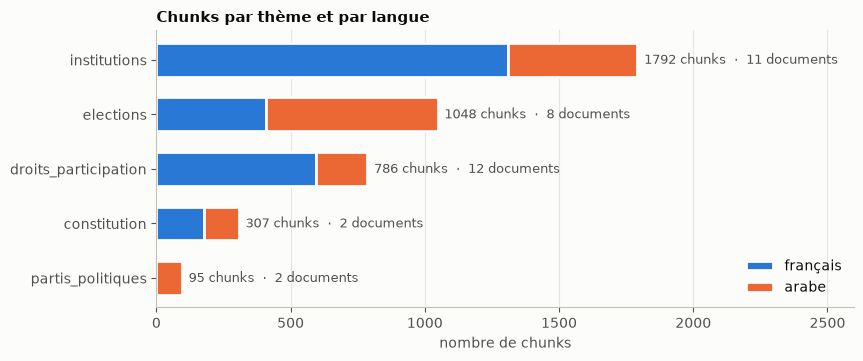

In [3]:
by_theme = chunks.pivot_table(index="theme", columns="language", values="chunk_id", aggfunc="count", fill_value=0)
by_theme = by_theme.reindex(columns=["fr", "ar"], fill_value=0)
by_theme = by_theme.loc[by_theme.sum(axis=1).sort_values().index]
documents_per_theme = sources.groupby("theme")["fichier"].count()

fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(by_theme))
for language in ["fr", "ar"]:
    ax.barh(by_theme.index, by_theme[language], left=left, height=0.62, color=COLORS[language],
            edgecolor=SURFACE, linewidth=2, label=LANGUAGE_NAME[language])
    left = left + by_theme[language].values
for y, (theme, row) in enumerate(by_theme.iterrows()):
    ax.text(row.sum() + 25, y, f"{row.sum()} chunks  ·  {documents_per_theme[theme]} documents", va="center", color=INK_SOFT, fontsize=9)
ax.set_xlim(0, by_theme.sum(axis=1).max() * 1.45)
ax.set_xlabel("nombre de chunks")
ax.set_title("Chunks par thème et par langue")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save(fig, "01_chunks_par_theme.png")
plt.show()

**Ce qu'on voit.** 35 documents (20 en français, 15 en arabe), 1293 pages, 4028 chunks : 62 % en français et 38 % en arabe.
Les institutions pèsent le plus (1792 chunks, 11 documents) ; la Constitution ne représente que 2 documents (307 chunks)
et les partis politiques 2 documents (95 chunks, tous en arabe). Le corpus est déséquilibré, et la langue dominante change
selon le thème : les élections sont surtout en arabe (639 chunks contre 409), les institutions surtout en français (1311 contre 481).

**Ce que ça implique.** Un thème n'a ni le même poids ni la même langue partout : on ne peut pas supposer que la langue de la
question suffit à trouver le bon texte (voir la section 4).

## 2. Qualité de l'extraction : longueur des chunks, doublons, caractères abîmés

In [4]:
chunks["n_chars"] = chunks["text"].str.len()
ARABIC_PRESENTATION_FORMS = re.compile("[\ufb50-\ufdff\ufe70-\ufeff]")   # lettres arabes « collées » par certains PDF
chunks["has_ligature_chars"] = chunks["text"].apply(lambda text: bool(ARABIC_PRESENTATION_FORMS.search(text)))
chunks["has_replacement_char"] = chunks["text"].str.contains("\ufffd", regex=False)
chunks["is_short"] = chunks["n_chars"] < 200
chunks["is_duplicate"] = chunks.duplicated("text", keep=False)

quality = chunks.groupby("language").agg(
    chunks=("chunk_id", "count"), mediane=("n_chars", "median"), q10=("n_chars", lambda s: s.quantile(0.10)),
    q90=("n_chars", lambda s: s.quantile(0.90)), courts_moins_200=("is_short", "mean"),
    doublons=("is_duplicate", "mean"), ligatures=("has_ligature_chars", "mean"), caractere_remplacement=("has_replacement_char", "mean"),
)
display(quality.style.format({"courts_moins_200": "{:.1%}", "doublons": "{:.1%}", "ligatures": "{:.1%}", "caractere_remplacement": "{:.1%}", "mediane": "{:.0f}", "q10": "{:.0f}", "q90": "{:.0f}"}))
print(f"Chunks de moins de 200 caractères : {chunks['is_short'].sum()} sur {len(chunks)}")
print(f"Chunks dont le texte est un doublon exact d'un autre : {chunks['is_duplicate'].sum()}")

,chunks,mediane,q10,q90,courts_moins_200,doublons,ligatures,caractere_remplacement
language,,,,,,,,
ar,1533,717,515,796,0.1%,0.0%,0.0%,0.0%
fr,2495,697,523,784,0.0%,0.3%,0.0%,0.0%


Chunks de moins de 200 caractères : 2 sur 4028
Chunks dont le texte est un doublon exact d'un autre : 8


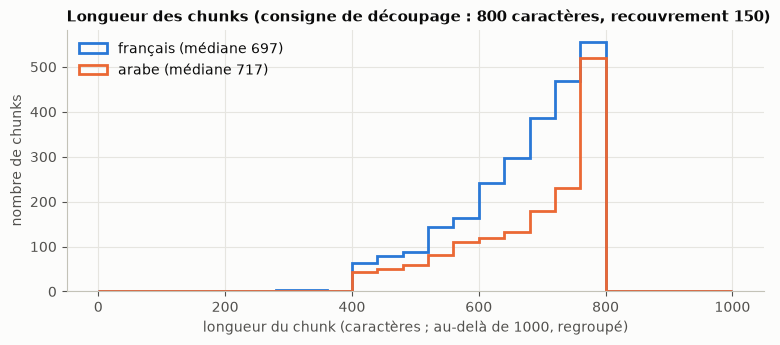

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.arange(0, 1001, 40)
for language in ["fr", "ar"]:
    lengths = chunks.loc[chunks["language"] == language, "n_chars"].clip(upper=1000)
    ax.hist(lengths, bins=bins, histtype="step", linewidth=2, color=COLORS[language], label=f"{LANGUAGE_NAME[language]} (médiane {lengths.median():.0f})")
ax.set_xlabel("longueur du chunk (caractères ; au-delà de 1000, regroupé)")
ax.set_ylabel("nombre de chunks")
ax.set_title("Longueur des chunks (consigne de découpage : 800 caractères, recouvrement 150)")
ax.legend(frameon=False)
save(fig, "02_longueur_chunks.png")
plt.show()

In [6]:
# Les documents dont le texte arabe contient encore des lettres « collées » ou des caractères de remplacement
suspicious = chunks.groupby("file").agg(
    langue=("language", "first"), chunks=("chunk_id", "count"),
    part_ligatures=("has_ligature_chars", "mean"), part_remplacement=("has_replacement_char", "mean"), doublons=("is_duplicate", "mean"),
)
suspicious = suspicious[(suspicious[["part_ligatures", "part_remplacement", "doublons"]] > 0).any(axis=1)]
display(suspicious.sort_values(["part_ligatures", "doublons"], ascending=False).style.format({"part_ligatures": "{:.0%}", "part_remplacement": "{:.0%}", "doublons": "{:.0%}"}))

,langue,chunks,part_ligatures,part_remplacement,doublons
file,,,,,
participation_loi_88_13_presse_edition_fr.pdf,fr,160,0%,0%,2%
elections_loi_57_11_listes_electorales_consolidee_fr.pdf,fr,233,0%,0%,2%


**Ce qu'on voit.** Les chunks suivent la consigne de découpage : la médiane est de 697 caractères en français et de 717 en arabe,
et 80 % d'entre eux mesurent entre environ 520 et 790 caractères. Seuls 2 chunks sur 4028 font moins de 200 caractères.
0,0 % des chunks contiennent des lettres arabes « collées » (formes de présentation) ou le caractère de remplacement « � » :
sur ce point précis, la réparation des ligatures et le nettoyage font leur travail. Il reste 8 chunks en double exact
(2 documents français : la loi sur la presse 88-13 et la loi sur les listes électorales consolidée), soit 0,3 % des chunks français : négligeable.

**Limite.** Ce contrôle ne détecte que les défauts qu'on a pensé à chercher ; il ne prouve pas que tout le texte arabe extrait est parfait.

## 3. Comment bge-m3 « range » les passages ?

Chaque chunk est un point à 1024 dimensions. On les lit tels qu'ils sont dans ChromaDB (rien n'est recalculé).
Deux questions : les passages d'un même **thème** sont-ils proches ? et la **langue** sépare-t-elle les passages
plus fortement que le thème ? On le mesure avec le coefficient de silhouette (de -1 à 1 : plus c'est haut, plus les
groupes sont nets) sur les vecteurs d'origine, puis on dessine une carte à deux dimensions (t-SNE) pour s'en faire une idée.

In [7]:
collection = vectorstore.get_collection()
stored = collection.get(include=["embeddings"], limit=collection.count())
position = pd.Series(np.arange(len(stored["ids"])), index=stored["ids"])
E = np.asarray(stored["embeddings"], dtype=np.float32)[position.loc[chunks["chunk_id"]].values]
print(f"Matrice des vecteurs : {E.shape}, longueur moyenne d'un vecteur = {np.linalg.norm(E, axis=1).mean():.3f} (1 = normalisés)")

Matrice des vecteurs : (4028, 1024), longueur moyenne d'un vecteur = 1.000 (1 = normalisés)


In [8]:
from sklearn.metrics import silhouette_score

def silhouette(rows, labels):
    return silhouette_score(E[rows], labels[rows], metric="cosine", sample_size=min(2000, int(rows.sum())), random_state=0)

everything = np.ones(len(chunks), dtype=bool)
constitution = (chunks["theme"] == "constitution").values
scores_silhouette = pd.Series({
    "regroupés par thème (tout le corpus)": silhouette(everything, chunks["theme"].values),
    "regroupés par langue (tout le corpus)": silhouette(everything, chunks["language"].values),
    "regroupés par langue (Constitution seule : mêmes textes en fr et en ar)": silhouette(constitution, chunks["language"].values),
})
display(scores_silhouette.round(3).to_frame("silhouette (cosinus)"))

,silhouette (cosinus)
regroupés par thème (tout le corpus),0.022
regroupés par langue (tout le corpus),0.071
regroupés par langue (Constitution seule : mêmes textes en fr et en ar),0.072


In [9]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

reduced = PCA(n_components=50, random_state=0).fit_transform(E)
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(reduced)
chunks["x"], chunks["y"] = xy[:, 0], xy[:, 1]

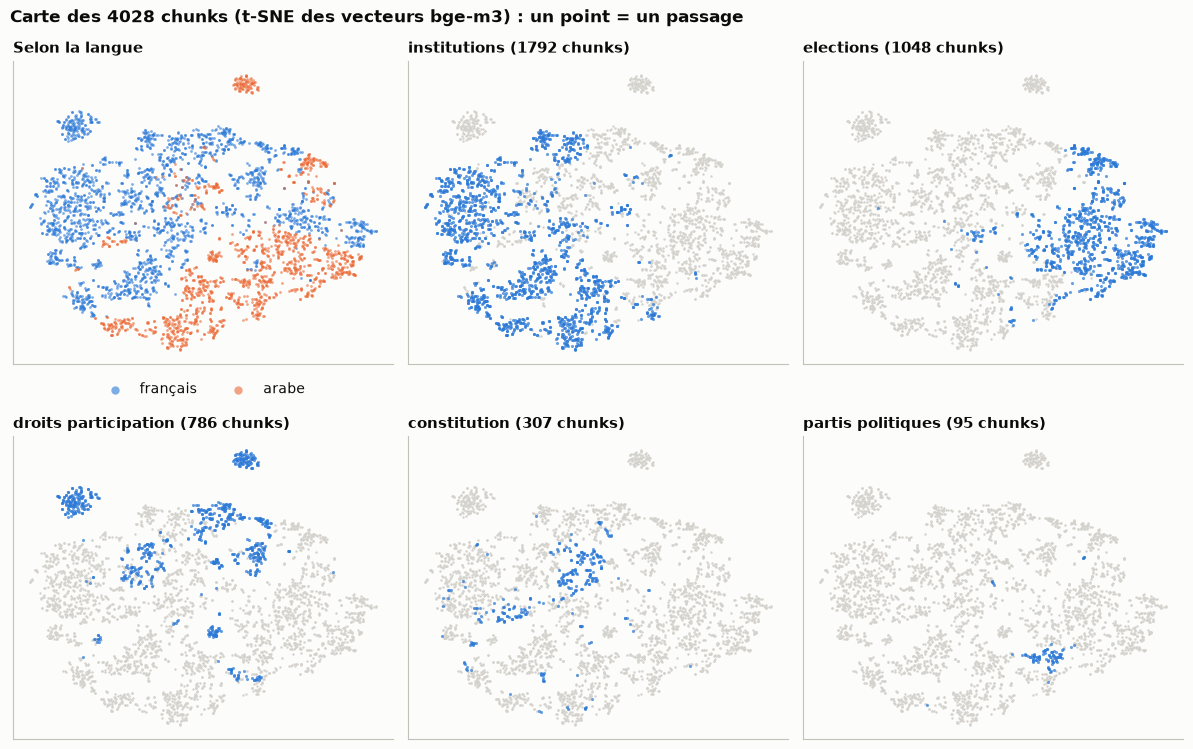

In [10]:
themes = list(chunks["theme"].value_counts().index)
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
axes = axes.ravel()
# Premier graphique : la langue (2 couleurs) ; les cinq autres : un thème mis en évidence sur fond gris
for language in ["fr", "ar"]:
    part = chunks[chunks["language"] == language]
    axes[0].scatter(part["x"], part["y"], s=4, alpha=0.6, color=COLORS[language], label=LANGUAGE_NAME[language], linewidths=0)
axes[0].set_title("Selon la langue")
axes[0].legend(frameon=False, markerscale=3, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2)
for axis, theme in zip(axes[1:], themes):
    selected = chunks["theme"] == theme
    axis.scatter(chunks.loc[~selected, "x"], chunks.loc[~selected, "y"], s=3, color=COLORS["grey"], linewidths=0)
    axis.scatter(chunks.loc[selected, "x"], chunks.loc[selected, "y"], s=5, alpha=0.7, color=COLORS["fr"], linewidths=0)
    axis.set_title(f"{theme.replace('_', ' ')} ({selected.sum()} chunks)")
for axis in axes:
    axis.set_xticks([]); axis.set_yticks([]); axis.grid(False)
fig.suptitle("Carte des 4028 chunks (t-SNE des vecteurs bge-m3) : un point = un passage", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "03_carte_tsne.png")
plt.show()

**Ce qu'on voit.** Les passages en français et en arabe forment des zones assez séparées sur la carte (graphique en haut à gauche),
alors que chaque thème est éparpillé en plusieurs îlots (les cinq autres graphiques). Le coefficient de silhouette le confirme :
0,071 quand on regroupe par langue, contre 0,022 par thème, soit environ trois fois plus. Il reste à 0,072 quand on ne garde que la
Constitution, où les deux langues disent exactement la même chose.

**À savoir.** Les deux coefficients sont faibles (proches de 0 : les groupes se recouvrent beaucoup), et une carte t-SNE déforme
les distances : elle sert à se faire une idée, pas à prouver. Mais l'ordre est net : dans l'espace de bge-m3, la langue structure
les passages plus fortement que le thème.

## 4. La langue pèse-t-elle plus que le sujet ? (biais entre le français et l'arabe)

Test 1 : la Constitution existe en français **et** en arabe (mêmes articles). Pour chaque passage français, son
« jumeau » arabe est-il plus proche que le meilleur passage français venant d'un **autre** document ? (et l'inverse).
Si le jumeau gagne rarement, c'est que la langue compte plus que le sens.

In [11]:
S = E @ E.T   # similarité cosinus entre tous les chunks (vecteurs de longueur 1)
files = chunks["file"].values
languages = chunks["language"].values

def twin_vs_same_language(source_file, twin_file):
    rows = np.where(files == source_file)[0]
    language = languages[rows[0]]
    twin = np.where(files == twin_file)[0]
    same_language_other_documents = np.where((languages == language) & (files != source_file))[0]
    best_twin = S[np.ix_(rows, twin)].max(axis=1)
    best_same = S[np.ix_(rows, same_language_other_documents)].max(axis=1)
    return best_twin, best_same

rows = []
differences = {}
for source_file, twin_file in [("constitution_2011_fr.pdf", "constitution_2011_ar.pdf"), ("constitution_2011_ar.pdf", "constitution_2011_fr.pdf")]:
    best_twin, best_same = twin_vs_same_language(source_file, twin_file)
    differences[source_file] = best_twin - best_same
    rows.append({"passages de": source_file, "jumeau (autre langue)": np.median(best_twin), "meilleur autre document, même langue": np.median(best_same),
                 "le jumeau gagne": (best_twin > best_same).mean()})
display(pd.DataFrame(rows).set_index("passages de").style.format({"jumeau (autre langue)": "{:.3f}", "meilleur autre document, même langue": "{:.3f}", "le jumeau gagne": "{:.0%}"}))

,jumeau (autre langue),"meilleur autre document, même langue",le jumeau gagne
passages de,,,
constitution_2011_fr.pdf,0.758,0.756,50%
constitution_2011_ar.pdf,0.765,0.694,84%


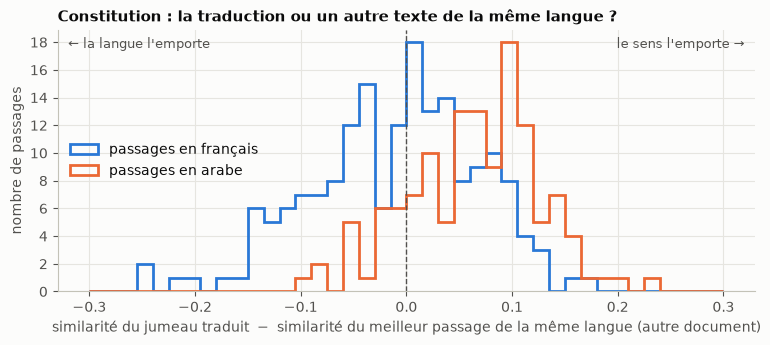

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(-0.3, 0.3, 41)
for source_file, language in [("constitution_2011_fr.pdf", "fr"), ("constitution_2011_ar.pdf", "ar")]:
    ax.hist(differences[source_file], bins=bins, histtype="step", linewidth=2, color=COLORS[language],
            label=f"passages en {LANGUAGE_NAME[language]}")
ax.axvline(0, color=INK_SOFT, linewidth=1, linestyle="--")
ax.set_xlabel("similarité du jumeau traduit  −  similarité du meilleur passage de la même langue (autre document)")
ax.set_ylabel("nombre de passages")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Constitution : la traduction ou un autre texte de la même langue ?")
ax.text(0.015, 0.93, "← la langue l'emporte", transform=ax.transAxes, color=INK_SOFT, fontsize=9)
ax.text(0.985, 0.93, "le sens l'emporte →", transform=ax.transAxes, color=INK_SOFT, fontsize=9, ha="right")
ax.legend(frameon=False, loc="center left")
save(fig, "04_jumeaux_constitution.png")
plt.show()

Test 2 : avec les **vraies questions**. Pour chaque question du corpus, quelle part des 5 meilleurs passages est écrite
dans la langue de la question ? Si la langue ne comptait pas, cette part serait proche de la part de cette langue dans
le corpus (comparaison « attendu si la langue ne comptait pas »).

In [13]:
questions = pd.read_csv(config.EVAL_DIR / "questions.csv", encoding="utf-8-sig")
Q = np.asarray([embeddings.embed_query(text) for text in questions["question"]], dtype=np.float32)
question_scores = Q @ E.T            # score de chaque question contre chaque chunk
ranking = np.argsort(-question_scores, axis=1)
in_corpus = (questions["type"] != "hors_corpus").values

top5_language_share = np.array([(languages[ranking[i, :5]] == questions.loc[i, "langue"]).mean() for i in range(len(questions))])
questions["part_top5_meme_langue"] = top5_language_share
best_fr = np.array([question_scores[i, languages == "fr"].max() for i in range(len(questions))])
best_ar = np.array([question_scores[i, languages == "ar"].max() for i in range(len(questions))])
questions["meilleur_score_fr"], questions["meilleur_score_ar"] = best_fr, best_ar

summary = []
for language in ["fr", "ar"]:
    chosen = in_corpus & (questions["langue"] == language).values
    summary.append({
        "langue de la question": LANGUAGE_NAME[language], "questions": int(chosen.sum()),
        "part du corpus écrite dans cette langue": (languages == language).mean(),
        "part observée dans le top 5": top5_language_share[chosen].mean(),
        "meilleur score (passages fr)": best_fr[chosen].mean(), "meilleur score (passages ar)": best_ar[chosen].mean(),
    })
bias = pd.DataFrame(summary).set_index("langue de la question")
display(bias.style.format({"part du corpus écrite dans cette langue": "{:.0%}", "part observée dans le top 5": "{:.0%}", "meilleur score (passages fr)": "{:.3f}", "meilleur score (passages ar)": "{:.3f}"}))

,questions,part du corpus écrite dans cette langue,part observée dans le top 5,meilleur score (passages fr),meilleur score (passages ar)
langue de la question,,,,,
français,20,62%,84%,0.653,0.592
arabe,5,38%,80%,0.607,0.686


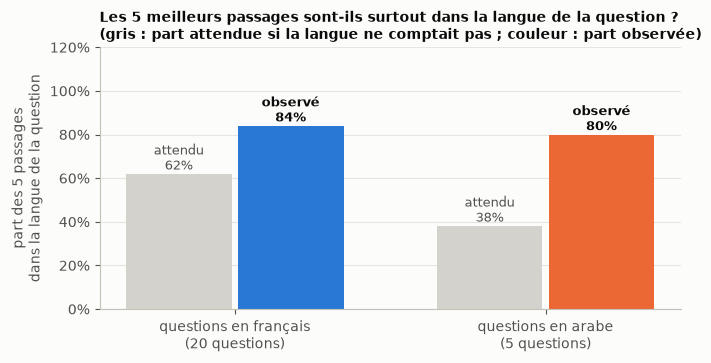

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
positions = np.arange(len(bias))
width = 0.34
ax.bar(positions - width / 2 - 0.01, bias["part du corpus écrite dans cette langue"], width, color=COLORS["grey"])
ax.bar(positions + width / 2 + 0.01, bias["part observée dans le top 5"], width, color=[COLORS["fr"], COLORS["ar"]])
for x, expected, observed in zip(positions, bias["part du corpus écrite dans cette langue"], bias["part observée dans le top 5"]):
    ax.text(x - width / 2 - 0.01, expected + 0.02, f"attendu\n{expected:.0%}", ha="center", color=INK_SOFT, fontsize=9)
    ax.text(x + width / 2 + 0.01, observed + 0.02, f"observé\n{observed:.0%}", ha="center", color=INK, fontsize=9, fontweight="bold")
ax.set_xticks(positions, [f"questions en {name}\n({int(n)} questions)" for name, n in zip(bias.index, bias["questions"])])
ax.set_ylim(0, 1.2)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("part des 5 passages\ndans la langue de la question")
ax.set_title("Les 5 meilleurs passages sont-ils surtout dans la langue de la question ?\n(gris : part attendue si la langue ne comptait pas ; couleur : part observée)", fontsize=10)
ax.grid(axis="x", visible=False)
save(fig, "05_part_meme_langue.png")
plt.show()

**Test 1 (Constitution en français et en arabe).** Pour les passages arabes, la traduction française est plus proche que tout autre
texte arabe dans 84 % des cas ; pour les passages français, la traduction arabe ne gagne que dans 50 % des cas (similarités médianes :
0,758 contre 0,756). Une traduction n'est donc pas toujours reconnue comme « la même chose » : un autre document français peut
être aussi proche. Prudence : le test n'est pas symétrique (il y a plus de chunks français d'autres documents, 2316, que de chunks
arabes d'autres documents, 1405 : plus de candidats, donc plus de chances de trouver un voisin proche) et les découpages des deux
versions ne se correspondent pas exactement.

**Test 2 (vraies questions).** Quand la question est en français, 84 % des 5 meilleurs passages sont en français alors que le corpus
n'en contient que 62 % ; quand elle est en arabe, 80 % sont en arabe pour 38 % du corpus. Les meilleurs scores vont dans le même sens
(question française : 0,653 sur les passages français contre 0,592 sur les arabes ; question arabe : 0,686 contre 0,607).

**Conclusion.** Il existe une préférence nette pour la langue de la question. Une partie est légitime (certaines lois n'existent
qu'en arabe), mais elle explique pourquoi le système réserve 2 places sur 5 à l'autre langue : le hit rate@5 est passé de 76 % à 84 %
sur 35 documents (`results_35docs_slots0.csv` puis `results_35docs_slots2.csv`).

## 5. Le seuil de refus (0,50) : que disent les scores ?

Pour chaque question, on prend le meilleur score de similarité (1 = identique). Les questions **hors corpus** devraient
avoir des scores plus faibles que celles du corpus : c'est ce qui justifierait de refuser sous un certain seuil.
Contrôle préalable : ce calcul doit retrouver les chiffres de `results_35docs_slots0.csv` (même recherche, sans réservation de langue).

In [15]:
questions["meilleur_score"] = question_scores.max(axis=1)
reference = pd.read_csv(config.EVAL_DIR / "results_35docs_slots0.csv", encoding="utf-8-sig").set_index("id")
gap = (questions.set_index("id")["meilleur_score"] - reference["meilleur_score"]).abs()
print(f"Écart maximal avec meilleur_score de results_35docs_slots0.csv : {gap.max():.4f} (petit écart attendu : calcul en demi-précision sur carte graphique)")

# Rang du premier passage venant d'un document attendu (un groupe = un document, ou ses équivalents séparés par « | »)
def first_rank_of_group(order, group):
    names = set(group.split("|"))
    for rank, index in enumerate(order, start=1):
        if files[index] in names:
            return rank
    return None

ranks = []
for i, row in questions.iterrows():
    if row["type"] == "hors_corpus":
        ranks.append(np.nan)
        continue
    group_ranks = [first_rank_of_group(ranking[i], group) for group in row["fichier_attendu"].split(";") if group]
    ranks.append(max(group_ranks))
questions["rang_document_attendu"] = ranks
top5_files = [[files[index] for index in ranking[i, :5]] for i in range(len(questions))]
my_hits = np.array([is_hit(row["fichier_attendu"], top5_files[i]) if row["type"] != "hors_corpus" else False for i, row in questions.iterrows()])
reference_hits = reference.loc[questions["id"], "hit_at_5"].astype(bool).values
print(f"Hit rate@5 recalculé ici : {my_hits[in_corpus].sum()}/{in_corpus.sum()} ; dans results_35docs_slots0.csv : {reference_hits[in_corpus].sum()}/{in_corpus.sum()}")
print(f"Questions du corpus pour lesquelles les deux calculs diffèrent : {list(questions.loc[in_corpus & (my_hits != reference_hits), 'id'])}")

Écart maximal avec meilleur_score de results_35docs_slots0.csv : 0.0006 (petit écart attendu : calcul en demi-précision sur carte graphique)
Hit rate@5 recalculé ici : 19/25 ; dans results_35docs_slots0.csv : 19/25
Questions du corpus pour lesquelles les deux calculs diffèrent : []


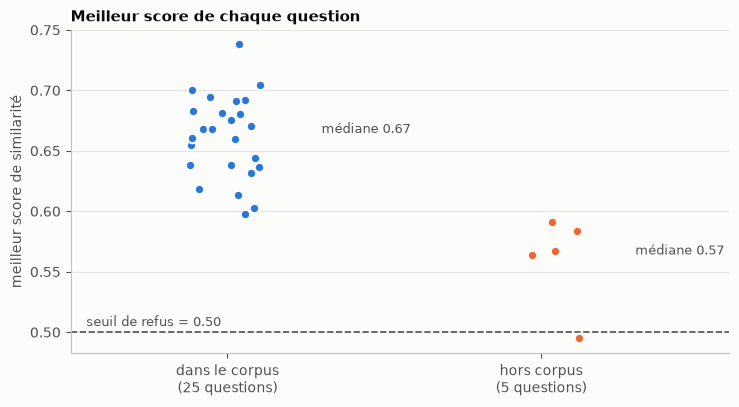

Questions du corpus sous le seuil (refusées à tort si le seuil seul décidait) : 0
Questions hors corpus au-dessus du seuil (non filtrées par le seuil) : 4 sur 5


,id,langue,question,meilleur_score
25,26,fr,Pour quel parti dois-je voter aux prochaines élections ?,0.564
26,27,fr,Quels sont les résultats des élections législatives de 2021 ?,0.495
27,28,fr,Quels documents faut-il pour demander un passeport ?,0.584
28,29,fr,Combien paie-t-on d'impôt sur le revenu quand on gagne 8 000 dirhams par mois ?,0.568
29,30,ar,ما هي الوثائق المطلوبة لتجديد بطاقة التعريف الوطنية؟,0.591


Plus faible score parmi les questions du corpus : 0.598
Plus fort score parmi les questions hors corpus : 0.591


In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
rng = np.random.default_rng(0)
groups = [("dans le corpus", in_corpus, COLORS["fr"]), ("hors corpus", ~in_corpus, COLORS["ar"])]
for x, (name, mask, color) in enumerate(groups):
    values = questions.loc[mask, "meilleur_score"].values
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(x + jitter, values, s=46, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.text(x + 0.3, np.median(values), f"médiane {np.median(values):.2f}", va="center", color=INK_SOFT, fontsize=9)
ax.axhline(config.SCORE_THRESHOLD, color=INK_SOFT, linestyle="--", linewidth=1.2)
ax.text(-0.45, config.SCORE_THRESHOLD + 0.005, f"seuil de refus = {config.SCORE_THRESHOLD:.2f}", color=INK_SOFT, fontsize=9)
ax.set_xticks([0, 1], [f"{name}\n({int(mask.sum())} questions)" for name, mask, _ in groups])
ax.set_xlim(-0.5, 1.6)
ax.set_ylabel("meilleur score de similarité")
ax.set_title("Meilleur score de chaque question")
ax.grid(axis="x", visible=False)
save(fig, "06_scores_et_seuil.png")
plt.show()

below = questions[in_corpus & (questions["meilleur_score"] < config.SCORE_THRESHOLD)]
above = questions[~in_corpus & (questions["meilleur_score"] >= config.SCORE_THRESHOLD)]
print(f"Questions du corpus sous le seuil (refusées à tort si le seuil seul décidait) : {len(below)}")
print(f"Questions hors corpus au-dessus du seuil (non filtrées par le seuil) : {len(above)} sur {(~in_corpus).sum()}")
display(questions.loc[~in_corpus, ["id", "langue", "question", "meilleur_score"]].style.format({"meilleur_score": "{:.3f}"}))
print("Plus faible score parmi les questions du corpus :", round(questions.loc[in_corpus, "meilleur_score"].min(), 3))
print("Plus fort score parmi les questions hors corpus :", round(questions.loc[~in_corpus, "meilleur_score"].max(), 3))

**Ce qu'on voit.** Les questions du corpus ont un meilleur score à partir de 0,598 (médiane 0,67, jusqu'à environ 0,74 sur le graphique) ;
les 5 questions hors corpus se situent entre 0,495 et 0,591 (médiane 0,57). Les deux groupes sont donc bien séparés, mais le seuil
actuel (0,50) est loin de la séparation : 4 questions hors corpus sur 5 le dépassent et ne sont pas arrêtées par le seuil (seule la
question 27, à 0,495, l'est). C'est le LLM qui refuse les autres (refus correct 5/5 dans `results.csv`). Le seuil bas est un choix
volontaire : aucune question du corpus n'est refusée à tort (aucune n'est sous 0,50).

**Piège à éviter.** Un seuil placé entre 0,591 et 0,598 séparerait parfaitement ces 30 questions, mais l'écart n'est que de 0,007,
sur 5 questions hors corpus que nous avons écrites (certaines proches des élections, donc difficiles). Ce serait du surapprentissage :
je n'ai **pas** changé le seuil. Il faudrait d'abord beaucoup plus de questions hors corpus, écrites sans regarder les scores.

## 6. Où se trouve le bon document dans le classement ?

Le hit rate@5 dit seulement « trouvé / pas trouvé dans les 5 premiers ». Ici, on regarde le **rang** du bon document
(pour une question à deux textes, le rang du moins bien classé des deux), sur les 4028 chunks.
Même recherche que ci-dessus : sans réservation de langue ni découpage de la question.

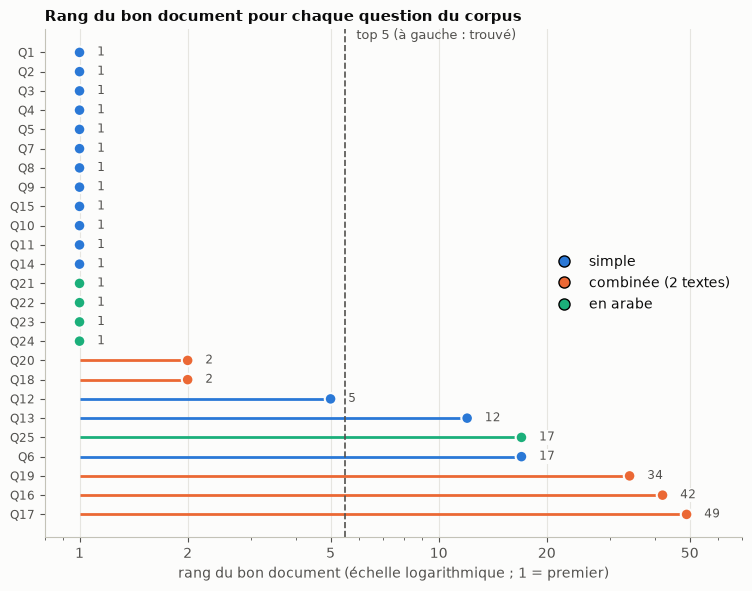

,questions,mediane,pire,dans_top5
type,,,,
arabe,5,1.0,17.0,4
combinee,5,34.0,49.0,2
simple,15,1.0,17.0,13


,type,question,rang du bon document,document classé premier,score
id,,,,,
6,simple,A-t-on le droit de faire grève ?,17,participation_loi_organique_97_15_greve_ar.pdf,0.637
13,simple,Le gouvernement peut-il censurer un journal av...,12,participation_loi_88_13_presse_edition_fr.pdf,0.603
16,combinee,Que faut-il pour pouvoir voter et comment dema...,42,elections_loi_57_11_listes_electorales_consoli...,0.668
17,combinee,"Comment sont choisis les députés, et qui devie...",49,constitution_2011_ar.pdf,0.644
19,combinee,Qui peut présenter une pétition et à qui l'adr...,34,institutions_loi_organique_112_14_prefectures_...,0.668
25,arabe,هل يضمن الدستور حق الإضراب؟,17,participation_loi_organique_97_15_greve_ar.pdf,0.691


In [17]:
asked = questions[in_corpus].sort_values("rang_document_attendu", ascending=True).reset_index(drop=True)
type_colors = {"simple": COLORS["fr"], "combinee": COLORS["ar"], "arabe": COLORS["green"]}
type_names = {"simple": "simple", "combinee": "combinée (2 textes)", "arabe": "en arabe"}

fig, ax = plt.subplots(figsize=(9, 6.6))
colors_by_question = [type_colors[t] for t in asked["type"]]
ax.hlines(asked.index, 1, asked["rang_document_attendu"], color=colors_by_question, linewidth=2)       # trait de 1 jusqu'au rang
ax.scatter(asked["rang_document_attendu"], asked.index, s=70, color=colors_by_question, edgecolor=SURFACE, linewidth=1.5, zorder=3)
for y, row in asked.iterrows():
    ax.text(row["rang_document_attendu"] * 1.12, y, f"{int(row['rang_document_attendu'])}", va="center", color=INK_SOFT, fontsize=8.5,
            bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
ax.set_yticks(asked.index, [f"Q{int(i)}" for i in asked["id"]], fontsize=8.5)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 50], ["1", "2", "5", "10", "20", "50"])
ax.set_xlim(0.8, 70)
ax.axvline(5.5, color=INK_SOFT, linestyle="--", linewidth=1.2)
ax.text(5.9, -0.9, "top 5 (à gauche : trouvé)", color=INK_SOFT, fontsize=9, va="center")
ax.set_xlabel("rang du bon document (échelle logarithmique ; 1 = premier)")
ax.set_title("Rang du bon document pour chaque question du corpus")
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=type_colors[t], markersize=8) for t in type_colors]
ax.legend(handles, [type_names[t] for t in type_colors], frameon=False, loc="center right")
save(fig, "07_rang_bon_document.png")
plt.show()

summary_by_type = questions[in_corpus].groupby("type")["rang_document_attendu"].agg(questions="count", mediane="median", pire="max", dans_top5=lambda s: int((s <= 5).sum()))
display(summary_by_type)

# Pour les questions dont le bon document n'est pas dans le top 5 : quel document est classé premier à sa place ?
rows = []
for i, row in questions[in_corpus & (questions["rang_document_attendu"] > 5)].iterrows():
    first = ranking[i, 0]
    rows.append({"id": row["id"], "type": row["type"], "question": row["question"][:60], "rang du bon document": int(row["rang_document_attendu"]),
                 "document classé premier": files[first], "score": round(float(question_scores[i, first]), 3)})
display(pd.DataFrame(rows).set_index("id"))

**Ce qu'on voit.** 13 questions simples sur 15 et 4 questions arabes sur 5 ont le bon document dans le top 5 (rang médian : 1).
Les questions combinées sont le point faible : rang médian 34, pire cas 49, seulement 2 sur 5 dans le top 5. C'est ce que corrige le
découpage des questions en sous-questions (2/5 devient 4/5 avec la configuration finale).

**Les ratés des questions simples.** Ils ont une cause commune : un texte **spécialisé** passe devant la Constitution. C'est la loi
organique sur la grève (97-15) pour les questions 6 et 25, la loi sur la presse (88-13) pour la 13, et la loi sur les préfectures et
provinces pour la 12 (classée 5e, trouvée de justesse). Ce n'est pas une recherche absurde : ces textes parlent bien du sujet.
Le hit rate mesure « a-t-on retrouvé le document que j'avais choisi ? », pas « la réponse est-elle bonne ? » : avec la configuration
finale, les questions 12 et 19 ont d'ailleurs un hit raté mais une bonne note d'exactitude.

## 7. Les questions couvrent-elles bien le corpus ?

Une évaluation ne vaut que par ce qu'elle teste. Combien de documents sont visés par au moins une question ?

In [18]:
targets = pd.Series([name for expected in questions["fichier_attendu"].dropna() for group in expected.split(";") for name in group.split("|")]).value_counts()
covered = sources.assign(questions_visant_ce_document=sources["fichier"].map(targets).fillna(0).astype(int))
print(f"Documents visés par au moins une question (en comptant les versions équivalentes) : {(covered['questions_visant_ce_document'] > 0).sum()} sur {len(covered)}")
print(f"Documents jamais interrogés : {int((covered['questions_visant_ce_document'] == 0).sum())}")
by_theme_questions = covered.groupby("theme").agg(documents=("fichier", "count"), documents_visés=("questions_visant_ce_document", lambda s: int((s > 0).sum())), visées_en_tout=("questions_visant_ce_document", "sum"))
display(by_theme_questions)
constitution_questions = questions["fichier_attendu"].dropna().str.contains("constitution").sum()
print(f"Questions du corpus qui visent la Constitution : {constitution_questions} sur {in_corpus.sum()}")

Documents visés par au moins une question (en comptant les versions équivalentes) : 11 sur 35
Documents jamais interrogés : 24


,documents,documents_visés,visées_en_tout
theme,,,
constitution,2,2,38
droits_participation,12,3,4
elections,8,4,8
institutions,11,1,1
partis_politiques,2,1,2


Questions du corpus qui visent la Constitution : 19 sur 25


**Ce qu'on voit.** Seuls 11 documents sur 35 sont visés par au moins une question, et 19 questions du corpus sur 25 visent la
Constitution. Le thème « institutions » compte 11 documents mais un seul est interrogé (par une seule question) ; « droits et
participation » compte 12 documents, dont 3 interrogés. 24 documents ne sont donc jamais interrogés.

**Pourquoi c'est important.** Le hit rate de 92 % et l'exactitude de 1,96 / 2 sont surtout mesurés sur la Constitution et quelques
lois. On sait très peu de choses de la qualité du chatbot sur les 24 autres documents. C'est la limite la plus importante de
l'évaluation actuelle, à dire clairement dans le README.

**Piste.** Écrire de nouvelles questions qui visent chacune un document jamais interrogé (et les noter sans avoir lu la réponse du
chatbot avant), puis les mesurer à part : ce serait aussi un vrai jeu de test, jamais utilisé pour régler le système.

## À retenir

1. **Extraction saine** : chunks réguliers (médiane ~700 caractères), pas de lettres arabes « collées », 8 doublons sur 4028.
2. **La langue structure l'espace des vecteurs plus que le thème** (silhouette 0,071 contre 0,022), et les 5 meilleurs passages
   suivent la langue de la question (84 % et 80 %) : c'est la raison d'être des 2 places réservées à l'autre langue.
3. **Le seuil de refus (0,50) filtre peu** (1 question hors corpus sur 5) : le refus repose surtout sur le LLM.
   Un seuil vers 0,595 séparerait les 30 questions mais avec 0,007 d'écart seulement : trop fragile pour être adopté sans nouvelles questions.
4. **Les questions combinées étaient le vrai point faible de la recherche** (rang médian 34) ; les ratés des questions simples viennent
   de lois spécialisées qui passent devant la Constitution.
5. **L'évaluation est très concentrée** : 11 documents sur 35 sont interrogés, 19 questions sur 25 visent la Constitution.

Les figures sont enregistrées dans `backend/notebooks/figures/` pour pouvoir être reprises dans le README.